# 02_3 Fine-tuning of the direct three-class classifier on PCA-reduced vectors

**Overview.** This notebook repeats the tuning of `02_2_vector_to_classifier_finetunning.ipynb` (same classes, same model, same search, selection and evaluation) with one change: the tile embeddings are the **PCA scores** of the UNI2-h CLS vectors, with `DIMENSION` components (512 by default; 256, 1024, ... can be chosen), instead of the original 1536-dimensional vectors. The classes are Non-cancer (N, PB, UDH, FEA), non-invasive atypia/neoplasia (ADH and DCIS) and invasive carcinoma (IC).

The reduced vectors are written by `01_2_vectors_to_pca_analysis.ipynb` to `pca_<DIMENSION>/UNI2-h/<slide>.pt`; this notebook only loads them. The PCA was fitted on tiles of the official Training slides only, so no Validation or Testing tile influenced its axes, and the Testing slides were only transformed. The folder and the names of the study and of the saved ensemble all carry `DIMENSION`, so results for different dimensions are kept apart.

A direct CLAM-MB is tuned by Bayesian optimisation of its learning rate, weight decay, dropout, weight of the coarse auxiliary loss, instance-loss sample size (`k_sample`) and tile cap (`max_tiles`). Every trial is a patient-grouped cross-validation over Training + Validation (`utils/mil_cv.py`); its score is the pooled out-of-fold macro-averaged F1. The chosen setting is confirmed with new seeds, its fold models are averaged into an ensemble, and the ensemble is evaluated once on the official Testing set and compared with the three-class model of `02_1_vector_to_classifier_experimentation.ipynb` (section 10) and with the ensemble of notebook 02_2, both trained on the 1536-dimensional vectors. No choice uses the Testing set.

```mermaid
flowchart TD
    subgraph IN["Inputs"]
        PCA[("pca_DIMENSION/UNI2-h/<br/>one .pt file per slide (from 01_2)")]
        LAB[("labels/BRACS.xlsx<br/>class, patient, official set")]
        FULL[("level_1/UNI2-h/<br/>1536-d vectors, Testing slides only (comparison)")]
        OLD[("classifier/final/<br/>models of 02_1 and 02_2")]
    end

    subgraph S3["3. Data"]
        D1["3.1 build_slide_table + load_bags"]
        D2["3.2 relabel_table<br/>Non-cancer / atypia-neoplasia / IC"]
        D3["3.3 make_cv_folds<br/>patient-grouped, stratified"]
    end

    subgraph S4["4. Bayesian optimisation"]
        B1["objective_factory + run_study<br/>TPE sampler, one trial = one 5-fold CV"]
        B2["trials_table + plot_tuning"]
    end

    subgraph S5["5-6. Selection and confirmation"]
        C1["select_setting<br/>recall floor, best macro-F1,<br/>one-standard-error rule"]
        C2["cross_validate, 2 repeats,<br/>new seeds, top settings"]
    end

    subgraph S7["7. Ensemble"]
        N1["oof_by_repeat + single_vs_ensemble<br/>out-of-fold, no Testing"]
    end

    subgraph S8["8. Testing set, used once"]
        E1["predict_ensemble<br/>all fold models"]
        E2["class_views + bootstrap_views<br/>plot_final_results"]
        E3["paired_bootstrap_views<br/>vs the 1536-d models of 02_1 and 02_2"]
    end

    OUT[("classifier/final/noncancer_noninvasive_invasive_pcaDIMENSION/<br/>ensemble_date-time.pt")]

    PCA --> D1
    LAB --> D1
    D1 --> D2
    D2 --> D3
    D3 --> B1
    B1 --> B2
    B2 --> C1
    C1 --> C2
    C2 --> N1
    N1 --> E1
    E1 --> E2
    E1 --> E3
    OLD --> E3
    FULL --> E3
    N1 --> OUT
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Standard-library imports and general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import optuna
import pandas as pd
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Scikit-learn version:', sklearn.__version__)
print('Optuna version:', optuna.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Scikit-learn version: 1.9.1
Optuna version: 5.1.0
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2


The model is trained on the GPU when one is available and on the CPU otherwise (`utils.device.get_device`).

In [2]:
# STEP 1: Select the device (pass e.g. get_device("cpu") to force the CPU)
from utils.device import get_device
DEVICE = get_device()

# STEP 2: Report it
print('Device:', DEVICE, '|', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else 'no GPU, running on the CPU')

Device: cuda | NVIDIA RTX PRO 4500 Blackwell


The project's own building blocks are imported here. The search, the selection rule and the ensemble file are in `utils/mil_tuning.py`; the data, model, cross-validation and metric code is shared with notebooks 02, 02_1 and 02_2.

In [3]:
# STEP 1: Standard-library imports
from pathlib import Path

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.mil_data import load_bags
from utils.mil_cv import cross_validate, fold_summary, make_cv_folds
from utils.mil_train import device_description, load_classifier, predict, predict_ensemble, set_seed
from utils.classification_metrics import evaluate_predictions
from utils.final_classifier import (bootstrap_views, class_views, format_differences, format_views, paired_bootstrap_views, plot_final_results, relabel_table, summary_across_sets)
from utils.mil_tuning import (DEFAULT_SPACE, eligible_trials, load_ensemble, objective_factory, oof_by_repeat, plot_tuning, run_study, save_ensemble, score_cv, select_setting, setting_from_row,
                              setting_kwargs, single_vs_ensemble, trials_table)

## 2. Constants

Every setting is defined here. `DIMENSION` is the number of PCA components: the vectors are read from `pca_<DIMENSION>/` (written by notebook 01_2, which must have been run with that dimension among its candidates) and the study and the ensemble are named after it. `FEATURES_FULL_DIR` holds the original 1536-dimensional vectors; they are read only for the Testing slides, because the models of notebooks 02_1 and 02_2 that serve as comparison need them. The searched parameters and their ranges are `SPACE`; the first trial is `BASELINE`, the setting of notebook 02_1, so it is scored on the same folds as the others. Everything else is fixed: class weighting, tile dropout, the weight of the slide loss in CLAM-MB, the number of epochs and the early-stopping patience. The coarse auxiliary loss uses two tiers, Non-cancer and lesion (atypia/neoplasia and invasive carcinoma). `MIN_CLASS_RECALL` is a floor on the out-of-fold recall of every class that a setting must reach to be chosen (one value for all classes, a dictionary with one value per class, or None); it is a clinical choice and is not tuned.

The budget is `N_TRIALS` trials, then the best `N_CONFIRM` settings are trained again with `REPEATS` repeats per fold. The ensemble has `N_FOLDS` x `REPEATS` models.

In [4]:
# Major variables
DIMENSION = 256                                                         # STEP 1: Number of PCA components (needs pca_<DIMENSION>/ from notebook 01_2; e.g. 256, 512, 1024)
FEATURES_ROOT = Path('/mnt/Scratch/phd_streamembed_features')           # STEP 2: Folder with level_1/ (original vectors) and the pca_<d>/ folders
FEATURES_DIR = FEATURES_ROOT / f'pca_{DIMENSION}'                       # STEP 3: Folder with one subfolder of .pt files per model (PCA vectors)
FEATURES_FULL_DIR = FEATURES_ROOT / 'level_1'                           # STEP 4: Original 1536-d vectors (only the Testing slides are read, for the comparisons of section 8)
MODEL_NAME = 'UNI2-h'                                                   # STEP 5: Subfolder with the per-slide features
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 6: Slide labels, patients and official split
MODEL_DIR = Path('classifier/final')                                    # STEP 7: Folder of the saved classifiers
SAVE_MODELS = True                                                      # STEP 8: Save the ensemble as ensemble_<date-time>.pt
SEED = 0                                                                # STEP 9: Seed of every random choice
N_FOLDS, EARLY_STOP_FRACTION = 5, 0.2                                   # STEP 10: Outer folds; share of the non-held-out slides used to pick the epoch (patient-grouped)
EPOCHS, PATIENCE = 100, 5                                               # STEP 11: Maximum epochs; early-stopping patience (counted after the warm-up)
WEIGHTING, TILE_DROPOUT, BAG_WEIGHT = 'sqrt', 0.5, 0.7                  # STEP 12: Class weighting, share of tiles removed per training bag, weight of the slide loss in CLAM-MB
N_TRIALS = 20                                                           # STEP 13: Trials of the Bayesian optimisation (finished trials; a restart continues the study)
STUDY_DIR = Path('outputs/02_3_tuning')                                 # STEP 14: Folder of the study (SQLite), the trials table
STUDY_NAME = f'three_class_pca{DIMENSION}'                              # STEP 15: Name of the study inside the database (one study per dimension)
MIN_CLASS_RECALL = 0.40                                                 # STEP 16: Smallest out-of-fold recall that every class must have (a float, a dict per class, or None)
N_CONFIRM, REPEATS = 2, 2                                               # STEP 17: Settings confirmed with new seeds; repeats per fold (models of the ensemble = folds x repeats)
N_BOOT = 1000                                                           # STEP 18: Bootstrap resamples (patients) for the intervals
THREE_MAPPING = {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer',
                 'ADH': 'Non-invasive atypia/neoplasia', 'DCIS': 'Non-invasive atypia/neoplasia', 'IC': 'Invasive carcinoma'}   # STEP 19: BRACS class -> group (order = model outputs)
TIERS_3 = {'non-cancer': ['Non-cancer'], 'lesion': ['Non-invasive atypia/neoplasia', 'Invasive carcinoma']}                      # STEP 20: Tiers of the coarse auxiliary loss
SPACE = DEFAULT_SPACE                                                   # STEP 21: Search ranges: (low, high) numeric, list = categorical (see utils/mil_tuning.py)
BASELINE = dict(lr=2e-4, weight_decay=1e-1, dropout=0.25, coarse_weight=0.0, k_sample=8, max_tiles=2048)   # STEP 22: First trial: the setting of notebook 02_1
FIXED = dict(epochs=EPOCHS, patience=PATIENCE, tile_dropout=TILE_DROPOUT, bag_weight=BAG_WEIGHT, weighted_val_loss=True, tiers=TIERS_3)   # STEP 23: train_model arguments that are not searched
STUDY_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

## 3. Data

### 3.1 Slides and tile embeddings

The bags of tile embeddings (PCA scores of the UNI2-h CLS tokens, `DIMENSION` components, from notebook 01_2) are loaded once; the slide table holds the official split of BRACS. The dimension of the loaded vectors is checked against `DIMENSION`.

In [5]:
# STEP 1: Label table with the official split and the bags of tile embeddings (float16)
table = build_slide_table(LABELS_FILE)
data = load_bags(FEATURES_DIR, MODEL_NAME, table)

# STEP 2: The vectors must have the chosen dimension
assert data['dim'] == DIMENSION, f"the files in {FEATURES_DIR} have {data['dim']} components, not {DIMENSION}"
print('PCA dimension:', data['dim'])

Loading bags:   0%|          | 0/547 [00:00<?, ?it/s]

Slides with features: 547 of 547  |  tiles 5,748,673  |  tiles per slide: median 9441, min 9, max 35287  |  dim 256
Per set (with features / labelled): Training 395/395, Validation 65/65, Testing 87/87
Tiling in the files: level 1, tile 448, stride 448
PCA dimension: 256


### 3.2 The three classes

Non-cancer groups N, PB, UDH and FEA; ADH and DCIS form one class; IC keeps its own class. The slides per class and part are listed.

In [6]:
# STEP 1: Relabel the table and the bags for the three classes
table3, classes3 = relabel_table(data['table'], THREE_MAPPING)
data3 = {**data, 'table': table3, 'classes': classes3}

# STEP 2: Slides per class and part
pd.crosstab(table3['label'], table3['set']).reindex(classes3)[['Training', 'Validation', 'Testing']]

set,Training,Validation,Testing
label,,,
Non-cancer,227,36,43
Non-invasive atypia/neoplasia,68,17,24
Invasive carcinoma,100,12,20


### 3.3 Cross-validation folds

The official Training and Validation slides are pooled and divided into patient-grouped, class-stratified folds; the Testing slides are in no fold. For every fold a part of the remaining slides is used to select the epoch and the rest to fit the model. The same folds are used by every trial, so the trials are compared on the same held-out slides.

In [7]:
# STEP 1: The folds (the Testing slides are left out of every fold)
folds = make_cv_folds(table3, N_FOLDS, SEED, EARLY_STOP_FRACTION)

# STEP 2: Slides and patients per part, and the held-out slides per class
fold_summary(folds, classes3)

,fold,fit,early stopping,held out,held-out patients,Non-cancer,Non-invasive atypia/neoplasia,Invasive carcinoma
0,0,293,74,93,34,53,17,23
1,1,295,72,93,33,53,17,23
2,2,295,73,92,33,53,17,22
3,3,294,75,91,29,52,17,22
4,4,297,72,91,29,52,17,22


## 4. Bayesian optimisation

One trial trains `N_FOLDS` models, one per fold, with a sampled setting and returns the pooled out-of-fold macro-averaged F1. The optimiser is the tree-structured Parzen estimator of optuna (Bergstra et al., 2011), which after ten random trials proposes settings from the results so far; the study is stored in SQLite, so a restart continues it. Every model is trained and stopped on the slides of its fold and scored on the held-out slides of the fold.

In [8]:
# STEP 1: The objective (one trial = one cross-validation) and the study
objective = objective_factory(data3, folds, DEVICE, FIXED, WEIGHTING, SEED, SPACE)
study = run_study(STUDY_NAME, f'sqlite:///{STUDY_DIR / "study.db"}', objective, N_TRIALS, SEED, BASELINE)

[I 2026-11-17 08:52:10,336] A new study created in RDB with name: three_class_pca256


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-11-17 08:52:57,675] Trial 0 finished with value: 0.7332776531559494 and parameters: {'lr': 0.0002, 'weight_decay': 0.1, 'dropout': 0.25, 'coarse_weight': 0.0, 'k_sample': 8, 'max_tiles': 2048}. Best is trial 0 with value: 0.7332776531559494.
[I 2026-11-17 08:54:05,038] Trial 1 finished with value: 0.7359436610690628 and parameters: {'lr': 0.000258817021493792, 'weight_decay': 0.05910317077425309, 'dropout': 0.40138168803582197, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 8192}. Best is trial 1 with value: 0.7359436610690628.
[I 2026-11-17 08:54:29,805] Trial 2 finished with value: 0.3350702884459569 and parameters: {'lr': 6.491242543802532e-05, 'weight_decay': 0.001122233999416817, 'dropout': 0.516309922773969, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 4096}. Best is trial 1 with value: 0.7359436610690628.
[I 2026-11-17 08:55:30,948] Trial 3 finished with value: 0.7216321010690656 and parameters: {'lr': 0.00011044976373595997, 'weight_decay': 0.08276957557192281, 

/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


[I 2026-11-17 09:02:10,856] Trial 9 finished with value: 0.7322227660383097 and parameters: {'lr': 0.00043908396455810564, 'weight_decay': 0.017451842382799464, 'dropout': 0.578041817361612, 'coarse_weight': 0.0, 'k_sample': 8, 'max_tiles': None}. Best is trial 8 with value: 0.7582001051439731.
[I 2026-11-17 09:03:02,399] Trial 10 finished with value: 0.7247123236409158 and parameters: {'lr': 0.0002889779516896165, 'weight_decay': 0.012589621169335485, 'dropout': 0.33796952032547867, 'coarse_weight': 0.5, 'k_sample': 16, 'max_tiles': 8192}. Best is trial 8 with value: 0.7582001051439731.
[I 2026-11-17 09:03:42,184] Trial 11 finished with value: 0.7525644259566331 and parameters: {'lr': 0.0004299761644964441, 'weight_decay': 0.0014155839188613967, 'dropout': 0.2764187844806335, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 2048}. Best is trial 8 with value: 0.7582001051439731.
[I 2026-11-17 09:04:22,260] Trial 12 finished with value: 0.7342586259309926 and parameters: {'lr': 0.00055

/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


[I 2026-11-17 09:08:13,805] Trial 17 finished with value: 0.7123902454776264 and parameters: {'lr': 0.000844255167814151, 'weight_decay': 0.09497938295672856, 'dropout': 0.3410937436622588, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 8192}. Best is trial 8 with value: 0.7582001051439731.
[I 2026-11-17 09:09:22,342] Trial 18 finished with value: 0.7279175322173455 and parameters: {'lr': 0.0002791974371095301, 'weight_decay': 0.01603804686610372, 'dropout': 0.5125741207352341, 'coarse_weight': 0.1, 'k_sample': 32, 'max_tiles': 8192}. Best is trial 8 with value: 0.7582001051439731.
[I 2026-11-17 09:10:21,707] Trial 19 finished with value: 0.7378064631616796 and parameters: {'lr': 0.0002859853567614994, 'weight_decay': 0.004815428133002022, 'dropout': 0.46910936879711596, 'coarse_weight': 0.1, 'k_sample': 16, 'max_tiles': 4096}. Best is trial 8 with value: 0.7582001051439731.


### 4.1 Trials

Every finished trial with its parameters, the pooled out-of-fold macro-F1, the out-of-fold recall and F1 of each class, the standard deviation over folds and the minutes it took. Trial 0 is the setting of notebook 02_1.

In [9]:
# STEP 1: The trials table, best first (ties: lower log-loss)
trials = trials_table(study)
trials.to_csv(STUDY_DIR / f'trials_{STUDY_NAME}.csv', index=False)
trials.round(3)

,trial,macro_f1,lr,weight_decay,dropout,coarse_weight,k_sample,max_tiles,f1_Invasive carcinoma,f1_Non-cancer,f1_Non-invasive atypia/neoplasia,fold_se,fold_std,log_loss,mean_best_epoch,minutes,recall_Invasive carcinoma,recall_Non-cancer,recall_Non-invasive atypia/neoplasia
0,8,0.758,0.000,0.029,0.386,0.1,16,8192.0,0.816,0.889,0.570,0.034,0.076,0.749,11.4,1.177,0.750,0.916,0.576
1,11,0.753,0.000,0.001,0.276,0.3,8,2048.0,0.823,0.872,0.563,0.028,0.062,0.599,10.2,0.661,0.768,0.890,0.576
2,4,0.747,0.000,0.003,0.164,0.3,4,2048.0,0.802,0.864,0.575,0.027,0.061,0.623,10.6,0.676,0.723,0.894,0.588
3,13,0.744,0.000,0.014,0.357,0.3,8,2048.0,0.822,0.872,0.538,0.036,0.082,0.571,12.2,0.742,0.741,0.932,0.494
4,19,0.738,0.000,0.005,0.469,0.1,16,4096.0,0.818,0.867,0.528,0.022,0.048,0.679,13.8,0.987,0.741,0.920,0.494
5,1,0.736,0.000,0.059,0.401,0.3,8,8192.0,0.806,0.880,0.522,0.043,0.096,0.740,10.4,1.121,0.741,0.932,0.482
6,12,0.734,0.001,0.002,0.293,0.3,16,2048.0,0.804,0.864,0.535,0.024,0.053,0.600,10.2,0.666,0.732,0.894,0.541
7,0,0.733,0.000,0.100,0.250,0.0,8,2048.0,0.808,0.866,0.526,0.049,0.109,0.572,13.8,0.787,0.732,0.924,0.482
8,7,0.733,0.000,0.045,0.166,0.0,8,8192.0,0.812,0.875,0.512,0.031,0.069,0.633,9.2,1.027,0.750,0.920,0.482
9,9,0.732,0.000,0.017,0.578,0.0,8,NaN,0.820,0.858,0.519,0.022,0.049,0.813,10.4,1.215,0.750,0.909,0.482


### 4.2 Optimisation history and importance

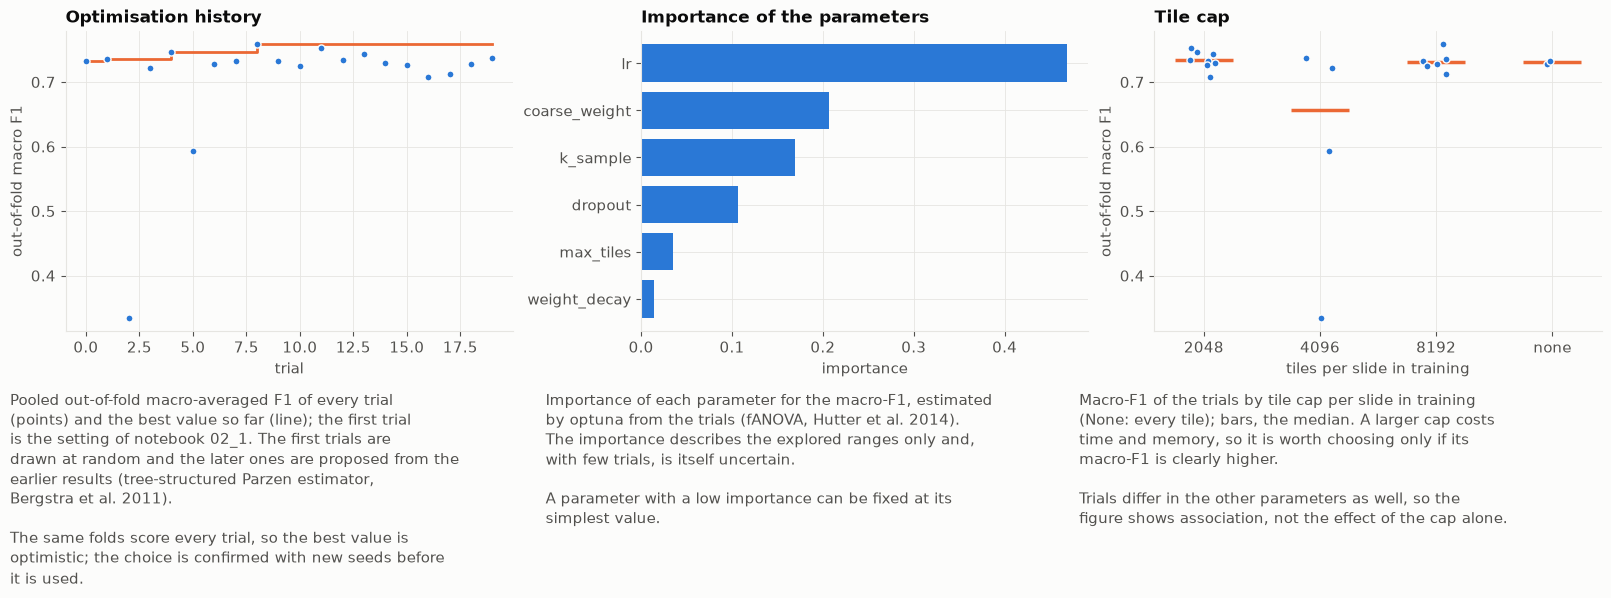

In [10]:
# STEP 1: Figure
fig_tuning = plot_tuning(study)

### 4.3 Best recall per class

The highest out-of-fold recall that any trial reached for each class. A recall floor above these values would remove every trial.

In [11]:
# STEP 1: Best out-of-fold recall of each class over the trials
trials[[f'recall_{c}' for c in classes3]].max().round(3).to_frame('best recall').T

,recall_Non-cancer,recall_Non-invasive atypia/neoplasia,recall_Invasive carcinoma
best recall,0.939,0.588,0.795


## 5. Selection

The final setting is chosen without the Testing set, in three steps: settings in which some class has an out-of-fold recall below `MIN_CLASS_RECALL` are removed; the best pooled macro-F1 is found among the rest; and among the settings within one standard error of it (the standard error of the fold macro-F1 values), the one with the higher dropout, then the higher weight decay is taken (one-standard-error rule, Hastie et al., 2009). Macro-F1 gives every class the same weight, which suits the smaller classes; sensitivity alone is not used, since it is maximised by assigning every slide to the class.

In [12]:
# STEP 1: Chosen setting and the candidates within one standard error of the best
chosen, candidates = select_setting(trials, MIN_CLASS_RECALL, classes3)
display(candidates.round(3))
print('Chosen: trial', int(chosen['trial']), setting_from_row(chosen))

,trial,macro_f1,lr,weight_decay,dropout,coarse_weight,k_sample,max_tiles,f1_Invasive carcinoma,f1_Non-cancer,f1_Non-invasive atypia/neoplasia,fold_se,fold_std,log_loss,mean_best_epoch,minutes,recall_Invasive carcinoma,recall_Non-cancer,recall_Non-invasive atypia/neoplasia
0,8,0.758,0.000,0.029,0.386,0.1,16,8192.0,0.816,0.889,0.570,0.034,0.076,0.749,11.4,1.177,0.750,0.916,0.576
1,11,0.753,0.000,0.001,0.276,0.3,8,2048.0,0.823,0.872,0.563,0.028,0.062,0.599,10.2,0.661,0.768,0.890,0.576
2,4,0.747,0.000,0.003,0.164,0.3,4,2048.0,0.802,0.864,0.575,0.027,0.061,0.623,10.6,0.676,0.723,0.894,0.588
3,13,0.744,0.000,0.014,0.357,0.3,8,2048.0,0.822,0.872,0.538,0.036,0.082,0.571,12.2,0.742,0.741,0.932,0.494
4,19,0.738,0.000,0.005,0.469,0.1,16,4096.0,0.818,0.867,0.528,0.022,0.048,0.679,13.8,0.987,0.741,0.920,0.494
5,1,0.736,0.000,0.059,0.401,0.3,8,8192.0,0.806,0.880,0.522,0.043,0.096,0.740,10.4,1.121,0.741,0.932,0.482
6,12,0.734,0.001,0.002,0.293,0.3,16,2048.0,0.804,0.864,0.535,0.024,0.053,0.600,10.2,0.666,0.732,0.894,0.541
7,0,0.733,0.000,0.100,0.250,0.0,8,2048.0,0.808,0.866,0.526,0.049,0.109,0.572,13.8,0.787,0.732,0.924,0.482
8,7,0.733,0.000,0.045,0.166,0.0,8,8192.0,0.812,0.875,0.512,0.031,0.069,0.633,9.2,1.027,0.750,0.920,0.482
9,9,0.732,0.000,0.017,0.578,0.0,8,NaN,0.820,0.858,0.519,0.022,0.049,0.813,10.4,1.215,0.750,0.909,0.482


Chosen: trial 14 {'lr': 0.0002950516473156989, 'weight_decay': 0.0015623501876462199, 'dropout': 0.39494101387518443, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 2048}


## 6. Confirmation with new seeds

The chosen setting and the next best settings are trained again with `REPEATS` repeats per fold and seeds that the search did not use, because the best value of many trials is optimistic. The same selection rule is then applied to these scores, and the final setting is the one it chooses.

In [13]:
# STEP 1: The settings to confirm: the chosen one, then the best remaining ones
order = [int(chosen['trial'])] + [int(t) for t in eligible_trials(trials, MIN_CLASS_RECALL, classes3)['trial'] if int(t) != int(chosen['trial'])]
confirm_trials = order[:N_CONFIRM]

# STEP 2: Cross-validation of each with REPEATS repeats and new seeds
cvs, rows = {}, []
for number in confirm_trials:
    setting = setting_from_row(trials[trials['trial'] == number].iloc[0])
    cvs[number] = cross_validate('clam_mb', data3, folds, DEVICE, WEIGHTING, REPEATS, SEED + 5000, **setting_kwargs(setting, FIXED))
    rows.append({'trial': number, **setting, **score_cv(cvs[number], classes3)})
confirmation = pd.DataFrame(rows).sort_values(['macro_f1', 'log_loss'], ascending=[False, True]).reset_index(drop=True)
confirmation.round(3)

,trial,lr,weight_decay,dropout,coarse_weight,k_sample,max_tiles,macro_f1,log_loss,recall_Non-cancer,recall_Non-invasive atypia/neoplasia,recall_Invasive carcinoma,f1_Non-cancer,f1_Non-invasive atypia/neoplasia,f1_Invasive carcinoma,fold_std,fold_se
0,8,0.0,0.029,0.386,0.1,16,8192,0.743,0.612,0.935,0.482,0.750,0.879,0.526,0.824,0.086,0.038
1,14,0.0,0.002,0.395,0.3,8,2048,0.737,0.529,0.924,0.494,0.741,0.877,0.519,0.814,0.081,0.036


The same selection rule is applied to the confirmation scores, which come from `REPEATS` models per fold, and gives the final setting and its fold models.

In [14]:
# STEP 1: The final setting by the same rule
final, final_candidates = select_setting(confirmation, MIN_CLASS_RECALL, classes3)
final_trial, final_setting = int(final['trial']), setting_from_row(final)
final_cv = cvs[final_trial]
print('Final: trial', final_trial, final_setting)

Final: trial 14 {'lr': 0.0002950516473156989, 'weight_decay': 0.0015623501876462199, 'dropout': 0.39494101387518443, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 2048}


## 7. Ensemble

The ensemble consists of the models of the final setting only: one per fold and repeat, `N_FOLDS` x `REPEATS` models, each trained on a different patient-grouped part of Training + Validation and stopped at its own epoch. A held-out slide is predicted by the models of its own fold and their probabilities are averaged, which gives the out-of-fold estimate below without the Testing set; on the Testing set all models predict every slide. Models of different settings are not mixed, because the same folds ranked the settings. The table compares each single repeat with the average of the repeats; the average over the confirmed settings is shown for comparison.

In [15]:
# STEP 1: Single repeats against the ensemble, on the out-of-fold slides
per_repeat = oof_by_repeat(final_cv, data3, folds, DEVICE)
display(single_vs_ensemble(final_cv, per_repeat, classes3).round(3))

# STEP 2: For comparison, the average over the confirmed settings (the same folds ranked them, so this is optimistic)
from sklearn.metrics import f1_score
mixed = np.mean([cvs[t]['proba'] for t in confirm_trials], axis=0)
print('Macro F1 of the ensemble of the final setting:', round(score_cv(final_cv, classes3)['macro_f1'], 3),
      '| of the average over the confirmed settings:', round(f1_score(final_cv['y'], mixed.argmax(1), average='macro'), 3))

,macro_f1,log_loss,recall_Non-cancer,recall_Non-invasive atypia/neoplasia,recall_Invasive carcinoma
single model (repeat 0),0.726,0.573,0.897,0.494,0.741
single model (repeat 1),0.745,0.565,0.916,0.541,0.732
ensemble (mean of repeats),0.737,0.529,0.924,0.494,0.741


Macro F1 of the ensemble of the final setting: 0.737 | of the average over the confirmed settings: 0.737


## 8. Evaluation on the Testing set

The Testing labels are read here for the first time. Every model of the ensemble predicts every Testing slide and the probabilities are averaged; the class with the highest probability is the prediction. For each class the measures are computed one class against the rest (for the macro row, the multi-class accuracy and the unweighted mean of the others), with 95% intervals from a bootstrap that resamples patients.

### 8.1 Confusion matrix, ROC curves and measures

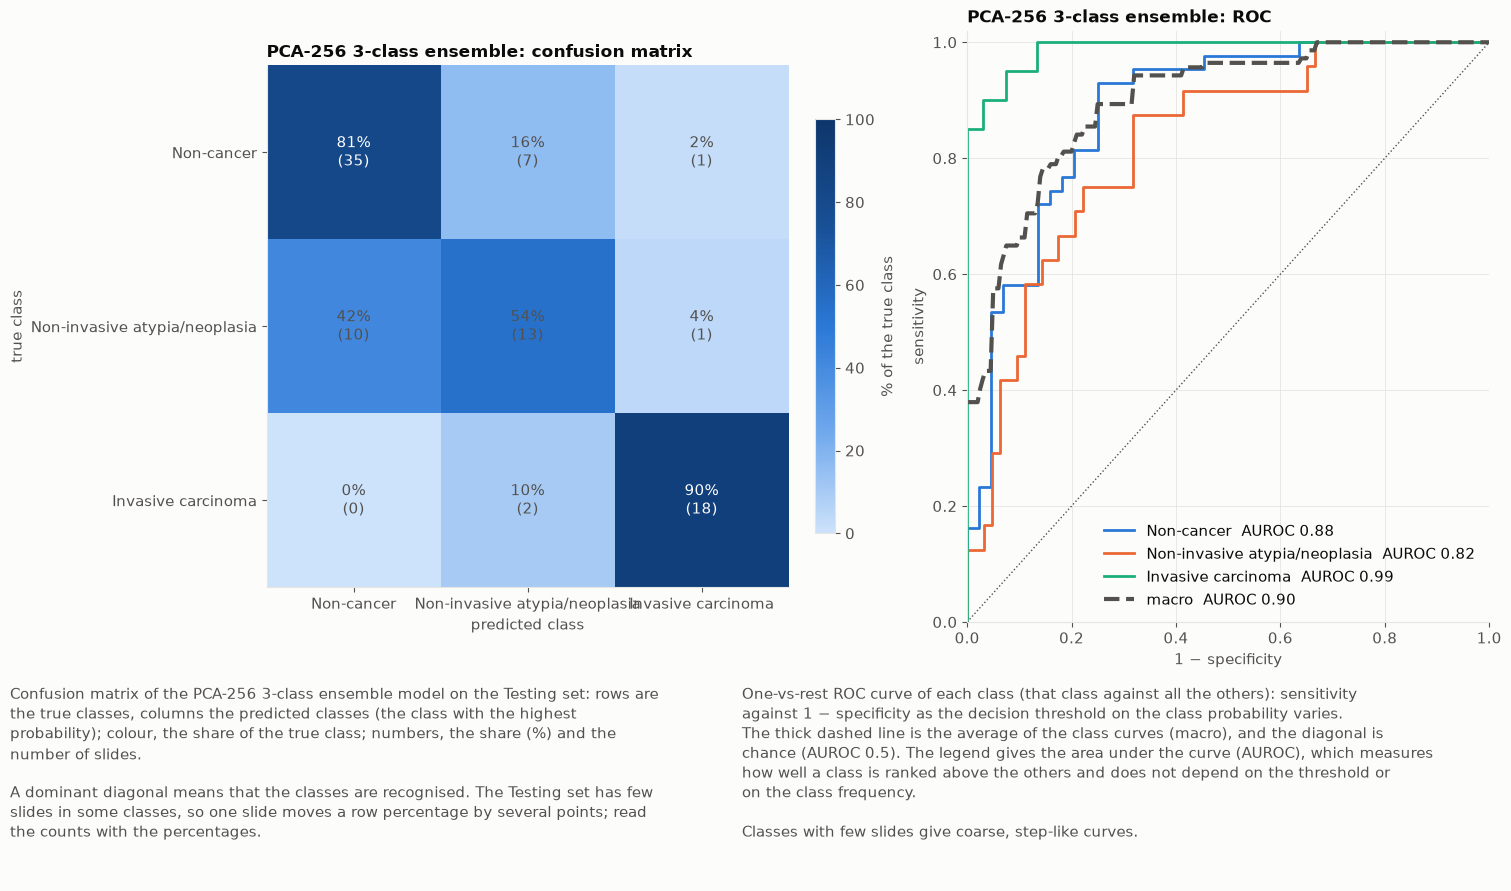

,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.793 [0.723, 0.875]","0.814 [0.719, 0.945]","0.773 [0.673, 0.889]","0.778 [0.625, 0.889]","0.795 [0.702, 0.871]","0.883 [0.814, 0.949]"
Non-invasive atypia/neoplasia,"0.770 [0.706, 0.845]","0.542 [0.316, 0.706]","0.857 [0.783, 0.946]","0.591 [0.450, 0.789]","0.565 [0.400, 0.678]","0.824 [0.751, 0.909]"
Invasive carcinoma,"0.954 [0.897, 0.991]","0.900 [0.750, 1.000]","0.970 [0.917, 1.000]","0.900 [0.714, 1.000]","0.900 [0.769, 0.982]","0.988 [0.961, 1.000]"
macro,"0.759 [0.691, 0.836]","0.752 [0.689, 0.814]","0.867 [0.824, 0.914]","0.756 [0.678, 0.825]","0.754 [0.681, 0.811]","0.898 [0.852, 0.947]"


In [16]:
# STEP 1: Testing slides, in table order, and the ensemble probabilities
test = table3[table3['set'] == 'Testing'].reset_index(drop=True)
y_test = np.array([classes3.index(l) for l in test['label']])
patients_test = test['patient'].to_numpy()
proba_test = predict_ensemble(final_cv['runs'], data3, test['slide'].tolist(), DEVICE)['proba']

# STEP 2: Measures with patient-bootstrap intervals, figure and table
NAME = f'PCA-{DIMENSION} 3-class ensemble'
evaluation = evaluate_predictions(y_test, proba_test, classes3)
views = {NAME: class_views(y_test, proba_test, classes3)}
intervals = {NAME: bootstrap_views(y_test, proba_test, patients_test, classes3, N_BOOT, SEED)}
fig_test = plot_final_results(NAME, evaluation['confusion'], y_test, proba_test, classes3)
display(format_views(views[NAME], intervals[NAME]))

### 8.2 Original vectors of the Testing slides

The comparison models of notebooks 02_1 and 02_2 were trained on the 1536-dimensional vectors, so they must score the original vectors of the Testing slides; only these slides are read at full dimension. The slides are the same as above, in the same order.

In [17]:
# STEP 1: The original CLS vectors of the Testing slides, with the three-class labels
full = load_bags(FEATURES_FULL_DIR, MODEL_NAME, data['table'][data['table']['set'] == 'Testing'])
full_table3, _ = relabel_table(full['table'], THREE_MAPPING)
data_full3 = {**full, 'table': full_table3, 'classes': classes3}

# STEP 2: Same slides, same order, as the PCA ensemble predicts
assert full['table']['slide'].tolist() == test['slide'].tolist(), 'the Testing slides differ between the PCA and the original vectors'
print('Original vector dimension:', full['dim'])

Loading bags:   0%|          | 0/87 [00:00<?, ?it/s]

Slides with features: 87 of 87  |  tiles 784,175  |  tiles per slide: median 7800, min 312, max 27685  |  dim 1536
Per set (with features / labelled): Training 0/0, Validation 0/0, Testing 87/87
Tiling in the files: level 1, tile 448, stride 448
Original vector dimension: 1536


### 8.3 Comparison with the direct three-class model of notebook 02_1

The model saved by section 10 of notebook 02_1 (`classifier/final/noncancer_adhdcis_ic/`, classes Non-cancer, ADH&DCIS and IC, the same slides in the same groups; trained on the 1536-dimensional vectors) predicts the same Testing slides. The difference (PCA ensemble minus that model) comes with a 95% interval from a paired patient bootstrap, in which both models are scored on the same resamples. An interval that contains zero is not distinguishable from no change at this sample size (87 slides, 31 patients).

In [18]:
# STEP 1: The previous direct three-class model (the latest file of its folder), on the same slides
previous_files = sorted((MODEL_DIR / 'noncancer_adhdcis_ic').glob('classifier_model_*.pt'))
if not previous_files:
    print('No classifier in', MODEL_DIR / 'noncancer_adhdcis_ic', ': run section 10 of notebook 02_1 first. Comparison skipped.')
else:
    previous = load_classifier(previous_files[-1], DEVICE)
    assert len(previous['classes']) == len(classes3), 'The two models must have the same number of classes'
    assert previous['classes'][0] == 'Non-cancer' and previous['classes'][-1] == 'IC', 'The class order of the two models must be the same (the group names differ)'
    proba_previous = predict(previous['model'], data_full3, test['slide'].tolist(), DEVICE, previous['scaler'])['proba']

    # STEP 2: Measures of both, and the paired bootstrap of the difference
    views['Direct 3-class, 1536-d (02_1)'] = class_views(y_test, proba_previous, classes3)
    display(summary_across_sets(views).round(3))
    differences = paired_bootstrap_views(y_test, proba_test, proba_test.argmax(1), proba_previous, proba_previous.argmax(1), patients_test, classes3, N_BOOT, SEED)
    display(format_differences(differences))

,accuracy,sensitivity,specificity,precision,f1,auroc
PCA-256 3-class ensemble,0.759,0.752,0.867,0.756,0.754,0.898
"Direct 3-class, 1536-d (02_1)",0.782,0.785,0.877,0.779,0.780,0.911


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"+0.000 [-0.084, +0.082]","+0.000 [-0.105, +0.162]","+0.000 [-0.159, +0.175]","+0.000 [-0.153, +0.098]","+0.000 [-0.078, +0.085]","-0.011 [-0.052, +0.034]"
Non-invasive atypia/neoplasia,"-0.023 [-0.118, +0.070]","+0.000 [-0.357, +0.296]","-0.032 [-0.115, +0.067]","-0.059 [-0.236, +0.154]","-0.026 [-0.281, +0.202]","-0.017 [-0.080, +0.069]"
Invasive carcinoma,"-0.023 [-0.079, +0.020]","-0.100 [-0.250, +0.000]","+0.000 [-0.053, +0.039]","-0.009 [-0.152, +0.107]","-0.052 [-0.164, +0.038]","-0.011 [-0.036, +0.000]"
macro,"-0.023 [-0.118, +0.070]","-0.033 [-0.141, +0.067]","-0.011 [-0.064, +0.046]","-0.023 [-0.133, +0.093]","-0.026 [-0.140, +0.081]","-0.013 [-0.046, +0.030]"


### 8.4 Comparison with the tuned ensemble of notebook 02_2

The ensemble saved by notebook 02_2 (`classifier/final/noncancer_noninvasive_invasive_tuned/`) uses the same classes, folds and search, but is trained on the 1536-dimensional vectors. Both ensembles predict the same Testing slides, and the difference (PCA minus original) comes with a 95% interval from the paired patient bootstrap. The comparison isolates the effect of the dimension reduction together with the setting that each search chose; the two searches are separate, so it is not a test of the reduction at a fixed setting.

In [19]:
# STEP 1: The ensemble of notebook 02_2 (the latest file of its folder), on the same slides
tuned_files = sorted((MODEL_DIR / 'noncancer_noninvasive_invasive_tuned').glob('ensemble_*.pt'))
if not tuned_files:
    print('No ensemble in', MODEL_DIR / 'noncancer_noninvasive_invasive_tuned', ': run notebook 02_2 first. Comparison skipped.')
else:
    tuned = load_ensemble(tuned_files[-1], DEVICE)
    assert tuned['classes'] == classes3, 'The two ensembles must have the same classes in the same order'
    proba_tuned = predict_ensemble(tuned['runs'], data_full3, test['slide'].tolist(), DEVICE)['proba']

    # STEP 2: Measures of both, and the paired bootstrap of the difference
    views['Tuned, 1536-d (02_2)'] = class_views(y_test, proba_tuned, classes3)
    display(summary_across_sets(views).round(3))
    differences = paired_bootstrap_views(y_test, proba_test, proba_test.argmax(1), proba_tuned, proba_tuned.argmax(1), patients_test, classes3, N_BOOT, SEED)
    display(format_differences(differences))

,accuracy,sensitivity,specificity,precision,f1,auroc
PCA-256 3-class ensemble,0.759,0.752,0.867,0.756,0.754,0.898
"Direct 3-class, 1536-d (02_1)",0.782,0.785,0.877,0.779,0.780,0.911
"Tuned, 1536-d (02_2)",0.805,0.804,0.889,0.817,0.810,0.935


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"-0.023 [-0.107, +0.064]","-0.023 [-0.141, +0.121]","-0.023 [-0.160, +0.108]","-0.022 [-0.156, +0.067]","-0.023 [-0.107, +0.075]","-0.038 [-0.087, +0.008]"
Non-invasive atypia/neoplasia,"-0.034 [-0.125, +0.059]","-0.083 [-0.381, +0.154]","-0.016 [-0.118, +0.088]","-0.061 [-0.286, +0.121]","-0.073 [-0.288, +0.110]","-0.062 [-0.132, +0.024]"
Invasive carcinoma,"-0.034 [-0.079, +0.000]","-0.050 [-0.154, +0.000]","-0.030 [-0.083, +0.000]","-0.100 [-0.286, +0.000]","-0.074 [-0.187, +0.000]","-0.010 [-0.032, +0.000]"
macro,"-0.046 [-0.133, +0.045]","-0.052 [-0.146, +0.041]","-0.023 [-0.070, +0.032]","-0.061 [-0.164, +0.035]","-0.057 [-0.154, +0.038]","-0.036 [-0.072, +0.008]"


## 9. Save

The ensemble is written to one file with the weights, scaler and settings of every model (`utils.mil_tuning.save_ensemble`; `load_ensemble` returns the models for `predict_ensemble`). The configuration records the searched ranges, the final setting and the study.

In [20]:
# STEP 1: What is needed to reproduce and to reuse the ensemble
config = dict(
    pca=dict(dimension=DIMENSION, vectors=str(FEATURES_DIR / MODEL_NAME), metadata=str(FEATURES_DIR / 'metadata.json')),
    seed=SEED, n_folds=N_FOLDS, repeats=REPEATS, early_stop_fraction=EARLY_STOP_FRACTION, weighting=WEIGHTING, fixed={k: v for k, v in FIXED.items() if k != 'tiers'}, tiers=TIERS_3,
    final_trial=final_trial, final_setting=final_setting, space={k: list(v) if isinstance(v, (tuple, list)) else v for k, v in SPACE.items()}, n_trials=N_TRIALS, min_class_recall=MIN_CLASS_RECALL,
    mapping=THREE_MAPPING, classes=classes3, features_dir=str(FEATURES_DIR), model_name=MODEL_NAME, tile_params=data['tile_params'], device=device_description(DEVICE),
    versions=dict(torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__, optuna=optuna.__version__), dropped_slides=data['missing'],
)

# STEP 2: Save the models of the ensemble
if SAVE_MODELS:
    path = save_ensemble(final_cv['runs'], MODEL_DIR / f'noncancer_noninvasive_invasive_pca{DIMENSION}', config)
    print('Ensemble of', len(final_cv['runs']), 'models saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Ensemble of 10 models saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/noncancer_noninvasive_invasive_pca256/ensemble_2026-11-17_09-14-28.pt
